In [4]:

# ACTIVIDAD 5 - FIGURA 2
# Validación del dataset y generación de versión limpia

import os
import subprocess
import pandas as pd
from IPython.display import display

# Descargar el repositorio público
repo = "https://github.com/esmvillafana-beep/Actividad5.git"

if not os.path.exists("Actividad5"):
    subprocess.run(
        ["git", "clone", repo],
        check=True
    )

# Ejecutar el script de preparación
resultado = subprocess.run(
    ["python", "fuentes/datos_prep.py"],
    cwd="Actividad5",
    capture_output=True,
    text=True
)

print("RESULTADO DE LA PREPARACIÓN")
print(resultado.stdout)

if resultado.returncode != 0:
    print(resultado.stderr)
    raise RuntimeError("La preparación de datos falló.")

# Comparar datos originales y limpios
base = "Actividad5/datos"

original = pd.read_csv(
    f"{base}/datos_ini/comentarios_originales_v1.csv"
)

limpio = pd.read_csv(
    f"{base}/datos_limp/comentarios_limpios_v1.csv"
)

print("\nVALIDACIÓN DEL DATASET")
print("Registros originales:", len(original))
print("Registros limpios:", len(limpio))
print("Registros eliminados:", len(original) - len(limpio))

print("\nDISTRIBUCIÓN DE SENTIMIENTOS")
distribucion = limpio["etiqueta_real"].value_counts()

display(
    distribucion.rename_axis("Sentimiento")
    .reset_index(name="Cantidad")
)

print("\nPRIMEROS CINCO REGISTROS DEL DATASET LIMPIO")
display(limpio.head())

print("\nARCHIVO GENERADO CORRECTAMENTE")
print("datos/datos_limp/comentarios_limpios_v1.csv")


RESULTADO DE LA PREPARACIÓN
Registros originales: 36; registros limpios: 36
Eliminados por nulos, vacíos o duplicados: 0
Distribución: {'POS': 12, 'NEG': 12, 'NEU': 12}
Archivo: /content/Actividad5/datos/datos_limp/comentarios_limpios_v1.csv


VALIDACIÓN DEL DATASET
Registros originales: 36
Registros limpios: 36
Registros eliminados: 0

DISTRIBUCIÓN DE SENTIMIENTOS


,Sentimiento,Cantidad
0,POS,12
1,NEG,12
2,NEU,12



PRIMEROS CINCO REGISTROS DEL DATASET LIMPIO


,texto,etiqueta_real
0,El copiloto me ayudó a encontrar la política v...,POS
1,Me encanta que indique la fuente de cada respu...,POS
2,La herramienta agilizó la preparación de mi re...,POS
3,Estoy satisfecho con la facilidad de uso del a...,POS
4,La búsqueda de procedimientos fue clara y rápida.,POS



ARCHIVO GENERADO CORRECTAMENTE
datos/datos_limp/comentarios_limpios_v1.csv


In [7]:

# ==========================================================
# ACTIVIDAD 5 - PUNTO 2
# CONFIGURACIÓN DE MLFLOW
# Banco Horizonte Digital
# ==========================================================

%pip install -q "mlflow>=3.0,<4.0" scikit-learn pandas matplotlib joblib

import mlflow
import sklearn
import pandas as pd

print("DEPENDENCIAS INSTALADAS CORRECTAMENTE")
print("MLflow:", mlflow.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)


DEPENDENCIAS INSTALADAS CORRECTAMENTE
MLflow: 3.17.1
Scikit-learn: 1.6.1
Pandas: 2.2.3


Repositorio disponible en: /content/Actividad5

DATASET CARGADO CORRECTAMENTE
Total de comentarios: 36

Distribución de sentimientos:


,Sentimiento,Cantidad
0,POS,12
1,NEG,12
2,NEU,12



Primeros registros:


,texto,etiqueta_real
0,El copiloto me ayudó a encontrar la política v...,POS
1,Me encanta que indique la fuente de cada respu...,POS
2,La herramienta agilizó la preparación de mi re...,POS
3,Estoy satisfecho con la facilidad de uso del a...,POS
4,La búsqueda de procedimientos fue clara y rápida.,POS


2026/10/19 00:25:29 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/19 00:25:29 INFO mlflow.store.db.utils: Updating database tables



CONFIGURACIÓN MLFLOW CORRECTA
Versión MLflow: 3.17.1
Tracking URI: sqlite:////content/Actividad5/mlflow.db
Nombre del experimento: Actividad5_Banco_Horizonte_Sentimientos
Experiment ID: 1
Directorio de artefactos: /content/Actividad5/mlflow_artifacts

DIVISIÓN DE LOS DATOS
Registros de entrenamiento: 27
Registros de prueba: 9

MÉTRICAS DEL MODELO PILOTO
accuracy: 0.2222
precision_macro: 0.1500
recall_macro: 0.2222
f1_macro: 0.1786


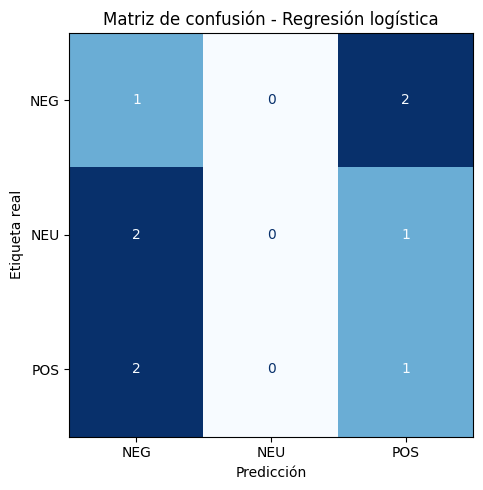


EJECUCIÓN REGISTRADA EN MLFLOW
Run ID: 6c9a048c84c44ccd96f15fea2d037316
Experimento: Actividad5_Banco_Horizonte_Sentimientos

VALIDACIÓN DE PARÁMETROS
algoritmo: Regresion_Logistica
representacion: TF-IDF
dataset_version: v1
random_state: 42
test_size: 0.25
max_features: 1000
ngram_range: 1-2
modelo_C: 1.0
modelo_max_iter: 1000
registros_entrenamiento: 27
registros_prueba: 9

VALIDACIÓN DE MÉTRICAS
accuracy: 0.2222
precision_macro: 0.1500
recall_macro: 0.2222
f1_macro: 0.1786

VALIDACIÓN DE ARTEFACTOS
evidencias/matriz_confusion.png
evidencias/predicciones.csv
evidencias/reporte_clasificacion.json
evidencias/resumen_ejecucion.json

Modelos registrados: 1

VALIDACIÓN MLFLOW COMPLETADA
Parámetros: CORRECTO
Métricas: CORRECTO
Artefactos: CORRECTO
Modelo entrenado: CORRECTO
Run ID: 6c9a048c84c44ccd96f15fea2d037316

RESUMEN DEL EXPERIMENTO


,Modelo,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Regresión logística,0.2222,0.15,0.2222,0.1786


In [8]:

# ==========================================================
# ACTIVIDAD 5 - PUNTO 2
# SEGUIMIENTO EXPERIMENTAL CON MLFLOW Y SQLITE
#
# Proyecto: Copiloto Operativo para Empleados
# Organización ficticia: Banco Horizonte Digital
#
# Objetivo:
# Validar el registro de parámetros, métricas,
# artefactos y modelos mediante MLflow.
# ==========================================================

import sys
import json
import shutil
import sqlite3
import hashlib
import platform
import subprocess
import tempfile
from pathlib import Path
from urllib.parse import urlparse, unquote

import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import mlflow
import mlflow.sklearn

from mlflow.tracking import MlflowClient

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from google.colab import files
from IPython.display import display


# ==========================================================
# 1. DESCARGAR EL REPOSITORIO DE GITHUB
# ==========================================================

REPO_URL = (
    "https://github.com/esmvillafana-beep/Actividad5.git"
)

ROOT = Path("/content/Actividad5")

if not ROOT.exists():
    print("Descargando repositorio desde GitHub...")

    subprocess.run(
        ["git", "clone", REPO_URL, str(ROOT)],
        check=True
    )
else:
    print("Repositorio disponible en:", ROOT)

ARCHIVO_DATOS = (
    ROOT
    / "datos"
    / "datos_limp"
    / "comentarios_limpios_v1.csv"
)

if not ARCHIVO_DATOS.exists():
    raise FileNotFoundError(
        f"No se encontró el dataset: {ARCHIVO_DATOS}"
    )

datos = pd.read_csv(ARCHIVO_DATOS)

columnas_requeridas = ["texto", "etiqueta_real"]

if not set(columnas_requeridas).issubset(datos.columns):
    raise ValueError(
        "El dataset no contiene las columnas requeridas."
    )

datos = datos[columnas_requeridas].copy()

datos["texto"] = datos["texto"].astype("string")
datos["etiqueta_real"] = (
    datos["etiqueta_real"]
    .astype("string")
    .str.strip()
    .str.upper()
)

if datos.isna().any().any():
    raise ValueError("El dataset contiene valores ausentes.")

if datos["texto"].str.strip().eq("").any():
    raise ValueError("Existen comentarios vacíos.")

if not set(datos["etiqueta_real"]).issubset(
    {"POS", "NEG", "NEU"}
):
    raise ValueError("Existen etiquetas no reconocidas.")

if len(datos) != 36:
    raise ValueError(
        f"Se esperaban 36 registros y se encontraron {len(datos)}."
    )

print("\n===================================")
print("DATASET CARGADO CORRECTAMENTE")
print("===================================")
print("Total de comentarios:", len(datos))

print("\nDistribución de sentimientos:")
display(
    datos["etiqueta_real"]
    .value_counts()
    .rename_axis("Sentimiento")
    .reset_index(name="Cantidad")
)

print("\nPrimeros registros:")
display(datos.head())


# ==========================================================
# 2. CONFIGURAR MLFLOW CON SQLITE
# ==========================================================

# SQLite almacena los experimentos, parámetros y métricas.
# Los modelos y archivos se guardan como artefactos.

BASE_DATOS = ROOT / "mlflow.db"
CARPETA_ARTEFACTOS = ROOT / "mlflow_artifacts"

CARPETA_ARTEFACTOS.mkdir(
    parents=True,
    exist_ok=True
)

TRACKING_URI = (
    f"sqlite:///{BASE_DATOS.resolve().as_posix()}"
)

mlflow.set_tracking_uri(TRACKING_URI)

NOMBRE_EXPERIMENTO = (
    "Actividad5_Banco_Horizonte_Sentimientos"
)

# El experimento se crea una sola vez.
experimento = mlflow.get_experiment_by_name(
    NOMBRE_EXPERIMENTO
)

if experimento is None:
    experiment_id = mlflow.create_experiment(
        name=NOMBRE_EXPERIMENTO,
        artifact_location=CARPETA_ARTEFACTOS.resolve().as_uri()
    )
else:
    experiment_id = experimento.experiment_id

mlflow.set_experiment(NOMBRE_EXPERIMENTO)

print("\n===================================")
print("CONFIGURACIÓN MLFLOW CORRECTA")
print("===================================")
print("Versión MLflow:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Nombre del experimento:", NOMBRE_EXPERIMENTO)
print("Experiment ID:", experiment_id)
print("Directorio de artefactos:", CARPETA_ARTEFACTOS)


# ==========================================================
# 3. PREPARAR LOS DATOS PARA ENTRENAMIENTO
# ==========================================================

X = datos["texto"].astype(str)
y = datos["etiqueta_real"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\n===================================")
print("DIVISIÓN DE LOS DATOS")
print("===================================")
print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))


# ==========================================================
# 4. CREAR PIPELINE DE CLASIFICACIÓN
# ==========================================================

modelo = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            max_features=1000,
            ngram_range=(1, 2)
        )
    ),
    (
        "clasificador",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            random_state=42
        )
    )
])

# Carpeta de resultados del piloto
CARPETA_RESULTADOS = (
    ROOT / "resultados" / "piloto_mlflow"
)

CARPETA_RESULTADOS.mkdir(
    parents=True,
    exist_ok=True
)

# Huella del dataset para identificar su versión
HASH_DATASET = hashlib.sha256(
    ARCHIVO_DATOS.read_bytes()
).hexdigest()


# ==========================================================
# 5. EJECUTAR Y REGISTRAR EL EXPERIMENTO
# ==========================================================

with mlflow.start_run(
    experiment_id=experiment_id,
    run_name="baseline_regresion_logistica"
) as ejecucion:

    RUN_ID = ejecucion.info.run_id

    # ------------------------------------------------------
    # 5.1 REGISTRAR PARÁMETROS
    # ------------------------------------------------------

    parametros = {
        "algoritmo": "Regresion_Logistica",
        "representacion": "TF-IDF",
        "dataset_version": "v1",
        "random_state": 42,
        "test_size": 0.25,
        "max_features": 1000,
        "ngram_range": "1-2",
        "modelo_C": 1.0,
        "modelo_max_iter": 1000,
        "registros_entrenamiento": len(X_train),
        "registros_prueba": len(X_test)
    }

    mlflow.log_params(parametros)

    mlflow.set_tags({
        "proyecto": "Banco Horizonte Digital",
        "actividad": "Actividad 5",
        "fase": "Validacion inicial de MLflow",
        "tipo_datos": "Comentarios sinteticos",
        "dataset_sha256": HASH_DATASET
    })

    # ------------------------------------------------------
    # 5.2 ENTRENAMIENTO
    # ------------------------------------------------------

    modelo.fit(X_train, y_train)

    predicciones = modelo.predict(X_test)

    # ------------------------------------------------------
    # 5.3 CALCULAR Y REGISTRAR MÉTRICAS
    # ------------------------------------------------------

    metricas = {
        "accuracy": accuracy_score(
            y_test, predicciones
        ),
        "precision_macro": precision_score(
            y_test,
            predicciones,
            average="macro",
            zero_division=0
        ),
        "recall_macro": recall_score(
            y_test,
            predicciones,
            average="macro",
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_test,
            predicciones,
            average="macro",
            zero_division=0
        )
    }

    mlflow.log_metrics(metricas)

    print("\n===================================")
    print("MÉTRICAS DEL MODELO PILOTO")
    print("===================================")

    for nombre, valor in metricas.items():
        print(f"{nombre}: {valor:.4f}")

    # ------------------------------------------------------
    # 5.4 ARTEFACTO: TABLA DE PREDICCIONES
    # ------------------------------------------------------

    tabla_predicciones = pd.DataFrame({
        "texto": X_test.to_numpy(),
        "etiqueta_real": y_test.to_numpy(),
        "prediccion": predicciones
    })

    tabla_predicciones.to_csv(
        CARPETA_RESULTADOS / "predicciones.csv",
        index=False,
        encoding="utf-8-sig"
    )

    # ------------------------------------------------------
    # 5.5 ARTEFACTO: REPORTE DE CLASIFICACIÓN
    # ------------------------------------------------------

    etiquetas = ["NEG", "NEU", "POS"]

    reporte = classification_report(
        y_test,
        predicciones,
        labels=etiquetas,
        zero_division=0,
        output_dict=True
    )

    with open(
        CARPETA_RESULTADOS / "reporte_clasificacion.json",
        "w",
        encoding="utf-8"
    ) as archivo:
        json.dump(
            reporte,
            archivo,
            ensure_ascii=False,
            indent=2
        )

    # ------------------------------------------------------
    # 5.6 ARTEFACTO: MATRIZ DE CONFUSIÓN
    # ------------------------------------------------------

    matriz = confusion_matrix(
        y_test,
        predicciones,
        labels=etiquetas
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=etiquetas
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(
        "Matriz de confusión - Regresión logística"
    )

    ax.set_xlabel("Predicción")
    ax.set_ylabel("Etiqueta real")

    plt.tight_layout()

    fig.savefig(
        CARPETA_RESULTADOS / "matriz_confusion.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # ------------------------------------------------------
    # 5.7 ARTEFACTO: RESUMEN DEL EXPERIMENTO
    # ------------------------------------------------------

    resumen = {
        "run_id": RUN_ID,
        "experimento": NOMBRE_EXPERIMENTO,
        "algoritmo": "Regresion_Logistica",
        "dataset": "comentarios_limpios_v1.csv",
        "dataset_sha256": HASH_DATASET,
        "registros_entrenamiento": len(X_train),
        "registros_prueba": len(X_test),
        "python": platform.python_version(),
        "mlflow": mlflow.__version__,
        "scikit_learn": sklearn.__version__,
        "metricas": metricas
    }

    with open(
        CARPETA_RESULTADOS / "resumen_ejecucion.json",
        "w",
        encoding="utf-8"
    ) as archivo:
        json.dump(
            resumen,
            archivo,
            indent=2,
            ensure_ascii=False
        )

    # ------------------------------------------------------
    # 5.8 REGISTRAR ARTEFACTOS EN MLFLOW
    # ------------------------------------------------------

    mlflow.log_artifacts(
        str(CARPETA_RESULTADOS),
        artifact_path="evidencias"
    )

    # ------------------------------------------------------
    # 5.9 REGISTRAR MODELO ENTRENADO
    # ------------------------------------------------------

    mlflow.sklearn.log_model(
        sk_model=modelo,
        name="modelo_baseline"
    )

print("\n===================================")
print("EJECUCIÓN REGISTRADA EN MLFLOW")
print("===================================")
print("Run ID:", RUN_ID)
print("Experimento:", NOMBRE_EXPERIMENTO)


# ==========================================================
# 6. VALIDAR LOS REGISTROS DE MLFLOW
# ==========================================================

cliente = MlflowClient()

ejecucion_guardada = cliente.get_run(RUN_ID)

print("\n===================================")
print("VALIDACIÓN DE PARÁMETROS")
print("===================================")

for nombre, valor in ejecucion_guardada.data.params.items():
    print(f"{nombre}: {valor}")

print("\n===================================")
print("VALIDACIÓN DE MÉTRICAS")
print("===================================")

for nombre, valor in ejecucion_guardada.data.metrics.items():
    print(f"{nombre}: {valor:.4f}")

print("\n===================================")
print("VALIDACIÓN DE ARTEFACTOS")
print("===================================")

artefactos = cliente.list_artifacts(
    RUN_ID,
    path="evidencias"
)

for archivo in artefactos:
    print(archivo.path)

# Verificar también que el modelo fue registrado.
modelos_registrados = cliente.search_logged_models(
    experiment_ids=[experiment_id]
)

print("\nModelos registrados:", len(modelos_registrados))

# Comprobaciones automáticas
assert len(ejecucion_guardada.data.params) >= 10, (
    "No se registraron todos los parámetros."
)

assert len(ejecucion_guardada.data.metrics) == 4, (
    "No se registraron las cuatro métricas."
)

assert len(artefactos) >= 4, (
    "Faltan artefactos del experimento."
)

assert len(modelos_registrados) >= 1, (
    "No se encontró el modelo registrado."
)

print("\n===================================")
print("VALIDACIÓN MLFLOW COMPLETADA")
print("===================================")
print("Parámetros: CORRECTO")
print("Métricas: CORRECTO")
print("Artefactos: CORRECTO")
print("Modelo entrenado: CORRECTO")
print("Run ID:", RUN_ID)


# ==========================================================
# 7. MOSTRAR TABLA RESUMEN
# ==========================================================

tabla_resumen = pd.DataFrame([
    {
        "Modelo": "Regresión logística",
        "Accuracy": metricas["accuracy"],
        "Precision_macro": metricas["precision_macro"],
        "Recall_macro": metricas["recall_macro"],
        "F1_macro": metricas["f1_macro"]
    }
])

print("\nRESUMEN DEL EXPERIMENTO")
display(tabla_resumen.round(4))


In [9]:

# ==========================================================
# ACTIVIDAD 5 - PUNTO 2
# RESPALDO DE EXPERIMENTOS MLFLOW
# ==========================================================

import shutil
import sqlite3
import tempfile

from pathlib import Path
from google.colab import files

ROOT = Path("/content/Actividad5")

base_datos = ROOT / "mlflow.db"
carpeta_artefactos = ROOT / "mlflow_artifacts"
carpeta_resultados = ROOT / "resultados" / "piloto_mlflow"

if not base_datos.exists():
    raise FileNotFoundError(
        "Primero ejecuta el experimento de MLflow."
    )

with tempfile.TemporaryDirectory() as temporal:

    destino = Path(temporal) / "Actividad5_Respaldo_MLflow"
    destino.mkdir(parents=True)

    # Copia consistente de la base SQLite
    with sqlite3.connect(str(base_datos)) as origen:
        with sqlite3.connect(str(destino / "mlflow.db")) as copia:
            origen.backup(copia)

    # Copiar artefactos registrados
    if carpeta_artefactos.exists():
        shutil.copytree(
            carpeta_artefactos,
            destino / "mlflow_artifacts"
        )

    # Copiar resultados del experimento
    if carpeta_resultados.exists():
        shutil.copytree(
            carpeta_resultados,
            destino / "resultados_piloto"
        )

    archivo_zip = shutil.make_archive(
        "/content/Actividad5_Respaldo_MLflow",
        "zip",
        root_dir=temporal,
        base_dir="Actividad5_Respaldo_MLflow"
    )

print("RESPALDO GENERADO CORRECTAMENTE")
print(archivo_zip)

files.download(archivo_zip)


RESPALDO GENERADO CORRECTAMENTE
/content/Actividad5_Respaldo_MLflow.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:

# ACTIVIDAD 5 - PUNTO 3
# Exportar evidencias de MLflow para GitHub

from pathlib import Path
import json
import zipfile

import pandas as pd
import mlflow
from mlflow.tracking import MlflowClient
from google.colab import files

ROOT = Path("/content/Actividad5")
BASE_DATOS = ROOT / "mlflow.db"

if not BASE_DATOS.exists():
    raise FileNotFoundError(
        "No encuentro mlflow.db. Debes ejecutar este "
        "bloque en la sesión donde registraste MLflow."
    )

mlflow.set_tracking_uri(
    f"sqlite:///{BASE_DATOS.resolve().as_posix()}"
)

NOMBRE_EXPERIMENTO = (
    "Actividad5_Banco_Horizonte_Sentimientos"
)

experimento = mlflow.get_experiment_by_name(
    NOMBRE_EXPERIMENTO
)

if experimento is None:
    raise RuntimeError(
        "No se encontró el experimento de MLflow."
    )

# Buscar la última ejecución finalizada
ejecuciones = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id],
    order_by=["start_time DESC"]
)

if ejecuciones.empty:
    raise RuntimeError("No existen ejecuciones registradas.")

finalizadas = ejecuciones[
    ejecuciones["status"] == "FINISHED"
]

if finalizadas.empty:
    raise RuntimeError(
        "No hay ejecuciones finalizadas correctamente."
    )

run_id = finalizadas.iloc[0]["run_id"]
cliente = MlflowClient()
registro = cliente.get_run(run_id)

# Preparar carpeta de resultados
destino = ROOT / "resultados" / "piloto_mlflow"
destino.mkdir(parents=True, exist_ok=True)

# Exportar parámetros
parametros = pd.DataFrame(
    [
        {"Parametro": clave, "Valor": valor}
        for clave, valor in registro.data.params.items()
    ]
)

parametros.to_csv(
    destino / "parametros_mlflow.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar métricas
metricas = pd.DataFrame(
    [
        {"Metrica": clave, "Valor": valor}
        for clave, valor in registro.data.metrics.items()
    ]
)

metricas.to_csv(
    destino / "metricas_mlflow.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar identificador y datos técnicos
(destino / "identificador_ejecucion.txt").write_text(
    f"Experimento: {NOMBRE_EXPERIMENTO}\n"
    f"Experiment ID: {experimento.experiment_id}\n"
    f"Run ID: {run_id}\n"
    f"Estado: {registro.info.status}\n",
    encoding="utf-8"
)

# Validar los artefactos locales existentes
esperados = [
    "predicciones.csv",
    "reporte_clasificacion.json",
    "matriz_confusion.png",
    "resumen_ejecucion.json"
]

faltantes = [
    nombre
    for nombre in esperados
    if not (destino / nombre).exists()
]

if faltantes:
    print(
        "Aviso: faltan archivos locales:",
        faltantes
    )
    print(
        "Puedes recuperarlos desde los artefactos "
        "de MLflow antes de subir el repositorio."
    )

# Comprobar los datos exportados
print("EVIDENCIAS MLFLOW PREPARADAS")
print("Run ID:", run_id)

print("\nPARÁMETROS:")
display(parametros)

print("\nMÉTRICAS:")
display(metricas)

print("\nARCHIVOS:")
for archivo in sorted(destino.iterdir()):
    if archivo.is_file():
        print(archivo.name)

# Generar ZIP que conserve la ruta resultados/piloto_mlflow
ZIP_SALIDA = Path(
    "/content/Actividad5_Punto3_Evidencias_GitHub.zip"
)

with zipfile.ZipFile(
    ZIP_SALIDA,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as comprimido:
    for archivo in destino.rglob("*"):
        if archivo.is_file():
            comprimido.write(
                archivo,
                arcname=str(
                    archivo.relative_to(ROOT)
                )
            )

print("\nZIP generado:", ZIP_SALIDA.name)

files.download(str(ZIP_SALIDA))


EVIDENCIAS MLFLOW PREPARADAS
Run ID: 6c9a048c84c44ccd96f15fea2d037316

PARÁMETROS:


,Parametro,Valor
0,algoritmo,Regresion_Logistica
1,representacion,TF-IDF
2,dataset_version,v1
3,random_state,42
4,test_size,0.25
5,max_features,1000
6,ngram_range,1-2
7,modelo_C,1.0
8,modelo_max_iter,1000
9,registros_entrenamiento,27



MÉTRICAS:


,Metrica,Valor
0,accuracy,0.222222
1,precision_macro,0.150000
2,recall_macro,0.222222
3,f1_macro,0.178571



ARCHIVOS:
identificador_ejecucion.txt
matriz_confusion.png
metricas_mlflow.csv
parametros_mlflow.csv
predicciones.csv
reporte_clasificacion.json
resumen_ejecucion.json

ZIP generado: Actividad5_Punto3_Evidencias_GitHub.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>